In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt


2. Input Stock List

In [2]:
# Choose 3–5 NSE stocks (yfinance uses .NS suffix)
stocks = ["TCS.NS", "RELIANCE.NS", "INFY.NS"]
benchmark = "^NSEI"   # Nifty50 index


3. Download 1-Year Data

In [3]:
import datetime

end = datetime.date.today()
start = end - datetime.timedelta(days=365)

data = yf.download(stocks + [benchmark], start=start, end=end)['Close']


/tmp/ipykernel_592776/2693357838.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(stocks + [benchmark], start=start, end=end)['Close']
[*********************100%***********************]  4 of 4 completed


4. Calculate Cumulative Returns

In [4]:
# Normalize to 100 at start
returns = data / data.iloc[0] * 100


5. Calculate CAGR (Compounded Annual Growth Rate)

In [5]:
def calculate_cagr(start_price, end_price, days):
    return (end_price/start_price) ** (365/days) - 1

cagr = {}
days = (data.index[-1] - data.index[0]).days

for col in data.columns:
    cagr[col] = calculate_cagr(data[col].iloc[0], data[col].iloc[-1], days)

cagr_df = pd.DataFrame(cagr, index=["CAGR"]).T
print(cagr_df.applymap(lambda x: f"{x:.2%}"))


                CAGR
INFY.NS      -22.01%
RELIANCE.NS   -5.66%
TCS.NS       -30.59%
^NSEI         -0.79%


/tmp/ipykernel_592776/551838762.py:11: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(cagr_df.applymap(lambda x: f"{x:.2%}"))


6. Plot Performance vs Nifty


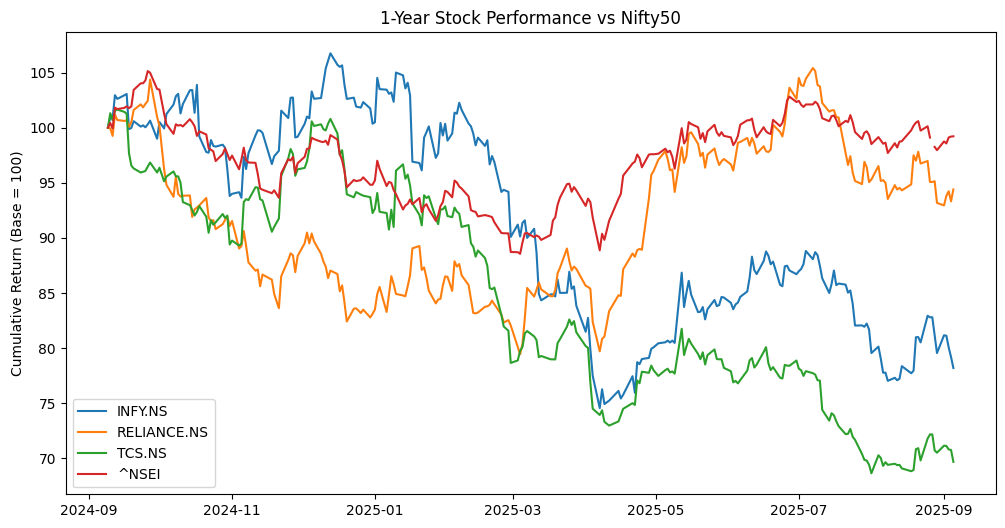

In [6]:
plt.figure(figsize=(12,6))
for col in returns.columns:
    plt.plot(returns.index, returns[col], label=col)

plt.title("1-Year Stock Performance vs Nifty50")
plt.ylabel("Cumulative Return (Base = 100)")
plt.legend()
plt.show()


In [7]:
for stock in stocks:
    stock_cagr = cagr[stock] * 100
    nifty_cagr = cagr[benchmark] * 100

    if stock_cagr > nifty_cagr:
        result = "outperforming"
    else:
        result = "underperforming"

    print(f"In last 1 year, {stock.replace('.NS','')} gave {stock_cagr:.2f}% return, "
          f"{result} Nifty50 ({nifty_cagr:.2f}%).")


In last 1 year, TCS gave -30.59% return, underperforming Nifty50 (-0.79%).
In last 1 year, RELIANCE gave -5.66% return, underperforming Nifty50 (-0.79%).
In last 1 year, INFY gave -22.01% return, underperforming Nifty50 (-0.79%).


7. Generate Report (like your example output)

In [8]:
for stock in stocks:
    stock_cagr = cagr[stock] * 100
    nifty_cagr = cagr[benchmark] * 100

    if stock_cagr > nifty_cagr:
        result = "outperforming"
    else:
        result = "underperforming"

    print(f"In last 1 year, {stock.replace('.NS','')} gave {stock_cagr:.2f}% return, "
          f"{result} Nifty50 ({nifty_cagr:.2f}%).")


In last 1 year, TCS gave -30.59% return, underperforming Nifty50 (-0.79%).
In last 1 year, RELIANCE gave -5.66% return, underperforming Nifty50 (-0.79%).
In last 1 year, INFY gave -22.01% return, underperforming Nifty50 (-0.79%).
